# CNN Assignment — Reading the Road: Traffic Sign Recognition

**Level:** Intermediate · **Suggested time:** 1–2 weeks · **Frameworks:** TensorFlow/Keras *or* PyTorch

## The scenario
You have joined the perception team at a self-driving car startup. The car's camera captures the road, and your job is to build a CNN that reads a cropped photo of a single traffic sign and says *which of 43 signs it is*. The data (GTSRB) is genuinely messy — variable size, lighting, blur, and class imbalance — and that is exactly where the interesting decisions live.

> **How this notebook works:** each step gives you a little starter code, a set of **Hints**, and a **TODO** checklist. You write the rest. Pick one framework and stick with it. Set a seed, use a GPU (Colab: *Runtime → Change runtime type → GPU*).


### Setup
**Hints**
- Import only what your chosen framework needs; delete the other block.
- Fix every random seed you can (`numpy`, and your framework's) so results are reproducible.

**TODO**
- [ ] Import your libraries
- [ ] Set a global `SEED`
- [ ] Detect and print whether a GPU is available


In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

# TODO: import your framework and set its seed; detect GPU
# PyTorch:  import torch, torchvision ; torch.manual_seed(SEED)
# TF/Keras: import tensorflow as tf ; tf.random.set_seed(SEED)

# Setup: PyTorch implementation (run in Google Colab with GPU enabled)
import copy, os, random, json
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import transforms
from torchvision.datasets import GTSRB

SEED = 42

def reset_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

reset_seed()
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUTPUT_DIR = Path('traffic_sign_outputs')
OUTPUT_DIR.mkdir(exist_ok=True)
print('PyTorch:', torch.__version__, '| Device:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('Tip: Colab > Runtime > Change runtime type > T4 GPU')

Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime


PyTorch: 2.14.1+cpu | Device: cpu
Tip: Colab > Runtime > Change runtime type > T4 GPU


---
## Part A — Explore the data  *(10%)*

**Hints**
- Load with `torchvision.datasets.GTSRB(root, split='train', download=True)` **or** `tensorflow_datasets.load('gtsrb')`, or a Kaggle folder/CSV.
- To build a label list fast in torchvision, the `(path, label)` pairs live in `dataset._samples`.
- Imbalance matters later (Part D): note which classes are rare *now*.
- Don't load every image just to measure sizes — sample a few hundred.

**TODO**
- [ ] A1: load train + test, print how many images in each and how many classes
- [ ] A2: show a 5×5 grid of random training images **with their labels**
- [ ] A3: plot a histogram of class frequencies; name the 3 rarest classes
- [ ] A4: report min / median / max image width and height


In [2]:
# A1
# TODO: load the datasets, then set NUM_CLASSES and print the counts
NUM_CLASSES = 43

DATA_DIR = './data'
raw_train = GTSRB(root=DATA_DIR, split='train', download=True)
raw_test = GTSRB(root=DATA_DIR, split='test', download=True)
train_labels = np.array([label for _, label in raw_train._samples], dtype=int)
test_labels = np.array([label for _, label in raw_test._samples], dtype=int)
assert sorted(np.unique(train_labels).tolist()) == list(range(NUM_CLASSES))
print(f'Train pool: {len(raw_train):,} | Official test: {len(raw_test):,} | Classes: {NUM_CLASSES}')

# GTSRB class labels; IDs are printed as well to make results unambiguous.
CLASS_NAMES = [
    'Speed 20','Speed 30','Speed 50','Speed 60','Speed 70','Speed 80',
    'End speed 80','Speed 100','Speed 120','No passing',
    'No passing >3.5t','Intersection priority','Priority road','Yield',
    'Stop','No vehicles','No >3.5t','No entry','Caution',
    'Curve left','Curve right','Double curve','Bumpy road','Slippery road',
    'Narrows right','Roadwork','Traffic lights','Pedestrians',
    'Children','Bicycles','Ice/snow','Wild animals','End restrictions',
    'Turn right','Turn left','Straight ahead','Straight/right',
    'Straight/left','Keep right','Keep left','Roundabout',
    'End no passing','End no passing >3.5t'
]
assert len(CLASS_NAMES) == NUM_CLASSES

100%|██████████| 187M/187M [00:16<00:00, 11.6MB/s]
100%|██████████| 89.0M/89.0M [00:08<00:00, 10.5MB/s]
100%|██████████| 99.6k/99.6k [00:00<00:00, 209kB/s]


Train pool: 26,640 | Official test: 12,630 | Classes: 43


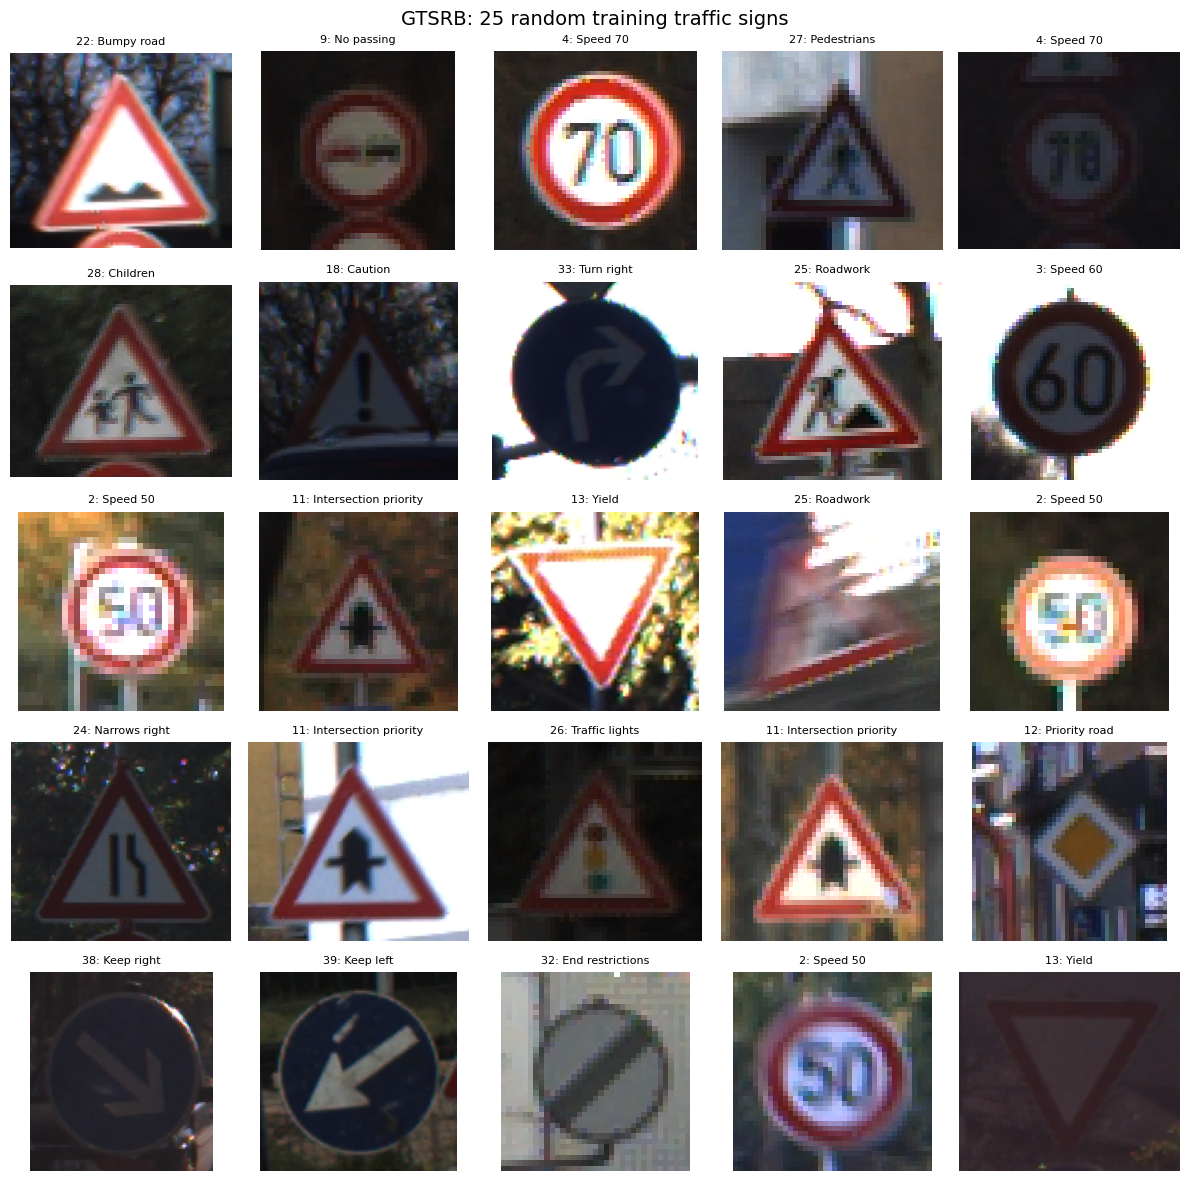

In [3]:
# A2 — grid of 25 random images with labels
# Hint: fig, axes = plt.subplots(5, 5, ...); loop, pick a random index, imshow, set_title(label)
# TODO

# A2: plot 25 random TRAIN images with actual labels.
rng = np.random.default_rng(SEED)
indices = rng.choice(len(raw_train), size=25, replace=False)
fig, axes = plt.subplots(5, 5, figsize=(12, 12))
for ax, idx in zip(axes.flat, indices):
    image, label = raw_train[int(idx)]
    ax.imshow(image)
    ax.set_title(f'{label}: {CLASS_NAMES[label]}', fontsize=8)
    ax.axis('off')
plt.suptitle('GTSRB: 25 random training traffic signs', fontsize=14)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'A2_samples.png', dpi=150)
plt.show()

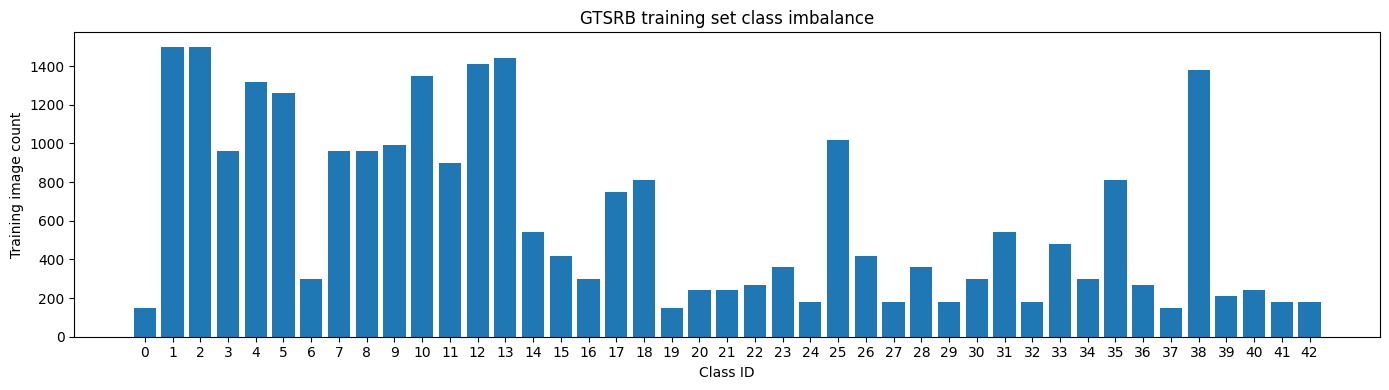

Three rarest classes:
   0 (Speed 20): 150 images
  19 (Curve left): 150 images
  37 (Straight/left): 150 images
Smallest/largest class ratio: 0.1


In [4]:
# A3 — class-frequency histogram
# Hint: from collections import Counter; count your label list; plt.bar(...)
# TODO

# A3: frequency and three rarest classes (computed, not guessed).
counts = np.bincount(train_labels, minlength=NUM_CLASSES)
RARE_CLASSES = np.argsort(counts)[:3].tolist()
fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(np.arange(NUM_CLASSES), counts)
ax.set(xlabel='Class ID', ylabel='Training image count',
       title='GTSRB training set class imbalance')
ax.set_xticks(np.arange(NUM_CLASSES))
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'A3_class_frequency.png', dpi=150)
plt.show()
print('Three rarest classes:')
for cls in RARE_CLASSES:
    print(f'  {cls:2d} ({CLASS_NAMES[cls]}): {counts[cls]} images')
print('Smallest/largest class ratio:', round(counts.min()/counts.max(), 3))

In [5]:
# A4 — image size distribution (sample a few hundred images)
# Hint: a PIL image exposes .size as (width, height)
# TODO

# A4: use PIL to inspect only 400 TRAIN image dimensions.
sample_n = min(400, len(raw_train))
size_indices = rng.choice(len(raw_train), size=sample_n, replace=False)
widths, heights = [], []
for idx in size_indices:
    file_path, _ = raw_train._samples[int(idx)]
    with Image.open(file_path) as img:
        width, height = img.size
    widths.append(width)
    heights.append(height)
for name, arr in [('Width', widths), ('Height', heights)]:
    print(f'{name}: min={np.min(arr)}, median={np.median(arr):.1f}, max={np.max(arr)} pixels')
print('Sizes are sampled estimates rather than full-dataset extrema.')

Width: min=26, median=43.0, max=164 pixels
Height: min=25, median=43.0, max=168 pixels
Sizes are sampled estimates rather than full-dataset extrema.


---
## Part B — Preprocess  *(10%)*

**Hints**
- Resize everything to one square size (32×32 or 48×48 are sensible). **Justify your choice in the report.**
- Scale pixels into [0,1] (torchvision `ToTensor()` already does this) or standardize per channel.
- Make the val split **stratified by class** so rare signs don't vanish from validation. A plain random split can drop a rare class entirely.
- Shuffle the *training* loader only; keep val/test in fixed order.

**TODO**
- [ ] B1/B2: define a resize+normalize transform (and a separate augmenting one later, in Part D)
- [ ] B3: build a stratified 80/20 train/val split
- [ ] B4: create train / val / test loaders (or `tf.data` pipelines) with batching


In [6]:
# B1 + B2 — transforms / preprocessing
IMG_SIZE = 32
BATCH_SIZE = 64
# TODO: build your resize + to-tensor/normalize transform, and re-load the datasets with it

# B1/B2: 32x32 keeps small signs compact and lowers GPU/memory requirements.
# ToTensor() turns RGB [0,255] into floating-point [0,1].
IMG_SIZE = 32
BATCH_SIZE = 64
EVAL_TRANSFORM = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])
# Training-only augmentation: geometric changes are modest; NO horizontal flipping.
AUG_TRANSFORM = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomAffine(degrees=12, translate=(0.10, 0.10), scale=(0.90, 1.10)),
    transforms.ColorJitter(brightness=0.20, contrast=0.20, saturation=0.12),
    transforms.ToTensor(),
])
plain_dataset = GTSRB(DATA_DIR, split='train', transform=EVAL_TRANSFORM)
aug_dataset = GTSRB(DATA_DIR, split='train', transform=AUG_TRANSFORM)
test_dataset = GTSRB(DATA_DIR, split='test', transform=EVAL_TRANSFORM)

In [7]:
# B3 — stratified 80/20 train/val split
# Hint: group training indices by class, shuffle each group, take 20% of EACH class for val.
#       from collections import defaultdict; then torch Subset / sklearn train_test_split(stratify=...)
# TODO

# B3: stratify ONLY the official training pool (never include official test).
all_indices = np.arange(len(raw_train))
train_idx, val_idx = train_test_split(
    all_indices, test_size=0.20, stratify=train_labels, random_state=SEED
)
assert not (set(train_idx) & set(val_idx))
assert len(train_idx) + len(val_idx) == len(raw_train)
assert len(np.unique(train_labels[train_idx])) == NUM_CLASSES
assert len(np.unique(train_labels[val_idx])) == NUM_CLASSES
train_counts = np.bincount(train_labels[train_idx], minlength=NUM_CLASSES)
print(f'Stratified train: {len(train_idx):,}; validation: {len(val_idx):,}; '
      f'untouched official test: {len(test_dataset):,}')

Stratified train: 21,312; validation: 5,328; untouched official test: 12,630


In [8]:
# B4 — data loaders
# Hint (PyTorch): DataLoader(ds, batch_size=BATCH_SIZE, shuffle=True) for train; shuffle=False otherwise
# TODO

# B4: validation and test are never shuffled or augmented.
NUM_WORKERS = 0 if os.name == 'nt' else 2
LOADER_KW = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
                 pin_memory=(DEVICE.type == 'cuda'))
train_loader = DataLoader(Subset(plain_dataset, train_idx), shuffle=True, **LOADER_KW)
aug_train_loader = DataLoader(Subset(aug_dataset, train_idx), shuffle=True, **LOADER_KW)
val_loader = DataLoader(Subset(plain_dataset, val_idx), shuffle=False, **LOADER_KW)
test_loader = DataLoader(test_dataset, shuffle=False, **LOADER_KW)
xb, yb = next(iter(train_loader))
print('Training batch:', tuple(xb.shape), '| target shape:', tuple(yb.shape),
      '| pixel range:', (float(xb.min()), float(xb.max())))

Training batch: (64, 3, 32, 32) | target shape: (64,) | pixel range: (0.019607843831181526, 1.0)


---
## Part C — Baseline CNN  *(25%)*

**Hints**
- Keep the baseline small: 2 blocks of Conv→ReLU→MaxPool, then Flatten→Dense→output.
- Output layer has **43 units**. In PyTorch leave them as raw logits (`CrossEntropyLoss` applies softmax internally); in Keras use `softmax` + `sparse_categorical_crossentropy`.
- Work out the flattened size: with IMG_SIZE=32 and two 2×2 pools you get 8×8 feature maps.
- Record **both** train and val metrics every epoch — you need them for the curves.

**TODO**
- [ ] C1: define the baseline CNN from scratch (no pretrained weights)
- [ ] C2: write/compile a training loop that logs train + val loss & accuracy per epoch
- [ ] C3: plot the learning curves
- [ ] C4: report **test accuracy** and interpret the curves (2–3 sentences)


In [9]:
# C1 — baseline architecture (fill in the layers)
# PyTorch sketch:
# class BaselineCNN(nn.Module):
#     def __init__(self, n_classes=NUM_CLASSES):
#         super().__init__()
#         self.features = nn.Sequential( ... )     # TODO: Conv2d/ReLU/MaxPool x2
#         self.classifier = nn.Sequential( ... )   # TODO: Flatten/Linear/ReLU/Linear
#     def forward(self, x): ...
# TODO

# C1: 2 Conv -> ReLU -> MaxPool blocks, then dense classifier, raw logits.
# Optional batchnorm enables one isolated experiment in Part D.
class BaselineCNN(nn.Module):
    def __init__(self, n_classes=NUM_CLASSES, batchnorm=False):
        super().__init__()
        def block(cin, cout):
            layers = [nn.Conv2d(cin, cout, kernel_size=3, padding=1)]
            if batchnorm:
                layers.append(nn.BatchNorm2d(cout))
            layers.extend([nn.ReLU(inplace=True), nn.MaxPool2d(2)])
            return layers
        self.features = nn.Sequential(*(block(3, 32) + block(32, 64)))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * (IMG_SIZE // 4) ** 2, 128),
            nn.ReLU(inplace=True),
            nn.Linear(128, n_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

probe = BaselineCNN().to(DEVICE)
with torch.no_grad():
    assert probe(torch.zeros(2, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)).shape == (2, NUM_CLASSES)
print(f'Baseline trainable parameters: {sum(p.numel() for p in probe.parameters()):,}')
del probe

Baseline trainable parameters: 549,355


In [10]:
# C2 — train the baseline, logging train & val metrics each epoch
EPOCHS = 15
# Hint (PyTorch): one function run_epoch(loader, train=bool) that returns (loss, acc);
#   remember model.train()/model.eval(), optimizer.zero_grad(), loss.backward(), optimizer.step()
# TODO

# C2: supervised training with best-validation checkpoint and early stopping.
# EPOCHS = 15
PATIENCE = 5
LR = 1e-3

def run_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train(is_train)
    n_total, n_correct, total_loss = 0, 0, 0.0
    with torch.set_grad_enabled(is_train):
        for x, y in loader:
            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)
            if is_train:
                optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = criterion(logits, y)
            if is_train:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * y.size(0)
            n_correct += (logits.argmax(1) == y).sum().item()
            n_total += y.size(0)
    return total_loss / n_total, n_correct / n_total

def fit_model(name, loader, batchnorm=False, class_weights=None):
    reset_seed(SEED)  # Identical initialization and shuffle seeds per comparison.
    model = BaselineCNN(batchnorm=batchnorm).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    weights = class_weights.to(DEVICE) if class_weights is not None else None
    train_loss_fn = nn.CrossEntropyLoss(weight=weights)
    val_loss_fn = nn.CrossEntropyLoss()  # validation losses remain comparable
    history = {k: [] for k in ('train_loss','train_acc','val_loss','val_acc')}
    best_acc, best_loss, best_epoch, best_state = -1.0, float('inf'), 0, None
    no_improve = 0
    print('\nTraining', name)
    for epoch in range(1, EPOCHS + 1):
        tl, ta = run_epoch(model, loader, train_loss_fn, optimizer)
        vl, va = run_epoch(model, val_loader, val_loss_fn)
        for k, v in [('train_loss',tl),('train_acc',ta),('val_loss',vl),('val_acc',va)]:
            history[k].append(v)
        if (va > best_acc + 1e-8) or (abs(va - best_acc) <= 1e-8 and vl < best_loss):
            best_acc, best_loss, best_epoch = va, vl, epoch
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1
        print(f'Epoch {epoch:02d} | train loss {tl:.4f} acc {ta:.2%} | '
              f'val loss {vl:.4f} acc {va:.2%}')
        if no_improve >= PATIENCE:
            print('Early stopping: no validation improvement for', PATIENCE, 'epochs')
            break
    model.load_state_dict(best_state)
    print(f'{name}: best validation accuracy={best_acc:.2%} at epoch {best_epoch}')
    return model, history, best_acc, best_epoch

baseline_model, baseline_history, baseline_val_acc, baseline_best_epoch = fit_model(
    'Baseline', train_loader)


Training Baseline
Epoch 01 | train loss 2.0223 acc 42.96% | val loss 0.8650 acc 72.33%
Epoch 02 | train loss 0.4472 acc 87.17% | val loss 0.2642 acc 92.83%
Epoch 03 | train loss 0.1851 acc 94.98% | val loss 0.1717 acc 94.95%
Epoch 04 | train loss 0.1074 acc 97.26% | val loss 0.1800 acc 94.56%
Epoch 05 | train loss 0.0726 acc 98.04% | val loss 0.0915 acc 97.79%
Epoch 06 | train loss 0.0558 acc 98.53% | val loss 0.1171 acc 96.81%
Epoch 07 | train loss 0.0432 acc 98.89% | val loss 0.0865 acc 97.88%
Epoch 08 | train loss 0.0413 acc 98.91% | val loss 0.0624 acc 98.57%
Epoch 09 | train loss 0.0182 acc 99.62% | val loss 0.0597 acc 98.76%
Epoch 10 | train loss 0.0272 acc 99.28% | val loss 0.0648 acc 98.48%
Epoch 11 | train loss 0.0122 acc 99.70% | val loss 0.0624 acc 98.76%
Epoch 12 | train loss 0.0366 acc 99.07% | val loss 0.0710 acc 98.25%
Epoch 13 | train loss 0.0289 acc 99.21% | val loss 0.0573 acc 98.89%
Epoch 14 | train loss 0.0064 acc 99.87% | val loss 0.0979 acc 98.24%
Epoch 15 | trai

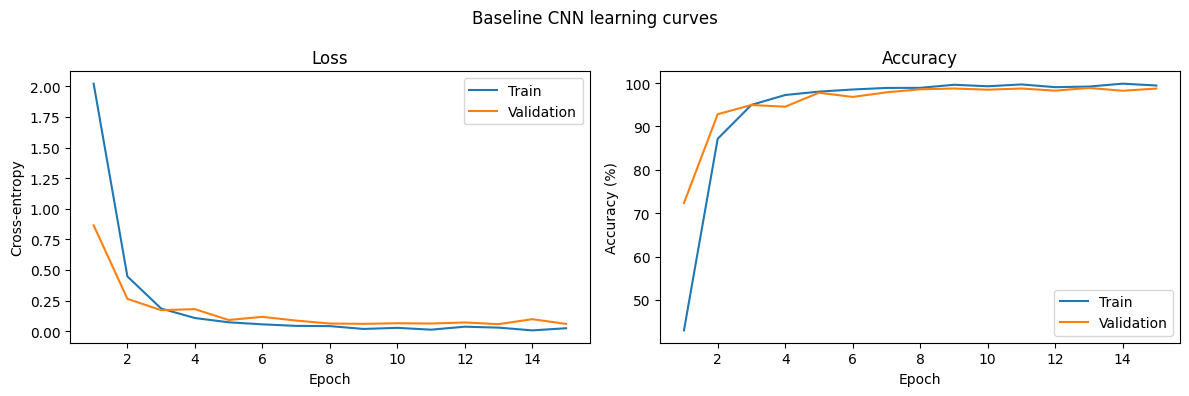

In [11]:
# C3 — plot loss and accuracy curves (train vs val)
# TODO

# C3: train vs validation learning curves from the baseline run.
def plot_curves(history, title, file_name=None):
    epochs = np.arange(1, len(history['train_loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history['train_loss'], label='Train')
    axes[0].plot(epochs, history['val_loss'], label='Validation')
    axes[0].set(title='Loss', xlabel='Epoch', ylabel='Cross-entropy')
    axes[0].legend()
    axes[1].plot(epochs, np.array(history['train_acc']) * 100, label='Train')
    axes[1].plot(epochs, np.array(history['val_acc']) * 100, label='Validation')
    axes[1].set(title='Accuracy', xlabel='Epoch', ylabel='Accuracy (%)')
    axes[1].legend()
    fig.suptitle(title)
    plt.tight_layout()
    if file_name:
        plt.savefig(OUTPUT_DIR / file_name, dpi=150)
    plt.show()
plot_curves(baseline_history, 'Baseline CNN learning curves', 'C3_baseline_curves.png')

In [12]:
# C4 — evaluate on the test set and print accuracy
# TODO

# C4: the requested baseline OFFICIAL test accuracy (not used to choose models).
test_loss_fn = nn.CrossEntropyLoss()
baseline_test_loss, baseline_test_acc = run_epoch(
    baseline_model, test_loader, test_loss_fn)
print(f'Baseline test accuracy: {baseline_test_acc:.2%} | test loss: {baseline_test_loss:.4f}')
train_acc_last = baseline_history['train_acc'][-1]
val_acc_last = baseline_history['val_acc'][-1]
gap = train_acc_last - val_acc_last
if gap > 0.05:
    curve_reading = 'Likely overfitting: training accuracy is more than 5 points above validation.'
elif train_acc_last < 0.80 and val_acc_last < 0.80:
    curve_reading = 'Likely underfitting: both training and validation accuracy are low.'
else:
    curve_reading = 'No strong overfitting signal from the final accuracy gap; inspect both loss curves.'
print(f'Last-epoch train/val accuracy gap: {gap*100:+.2f} percentage points.')
print(curve_reading)

Baseline test accuracy: 88.71% | test loss: 0.7403
Last-epoch train/val accuracy gap: +0.71 percentage points.
No strong overfitting signal from the final accuracy gap; inspect both loss curves.


**C4 interpretation (write here):** _Overfitting, underfitting, or healthy? What in the curves tells you?_

The following values are computed from the actual epoch logs by C4 (rather than assuming overfitting beforehand). Compare the training and validation loss curves; a persistent gap with rising validation loss suggests overfitting. The baseline test accuracy is printed above.

---
## Part D — Make it better  *(30%)*

Apply **at least three** techniques and measure **each** against the baseline.

**Hints**
- Change **one thing at a time** or you won't know what helped.
- Augmentation ideas: rotation, small shifts, zoom, brightness. **Do NOT flip horizontally** — it can turn a left-turn sign into a right-turn sign.
- Overfitting (val ≪ train)? → augmentation, dropout, batchnorm. Underfitting? → bigger/deeper net, train longer.
- Imbalance: pass class weights to the loss, or oversample rare classes.
- Transfer learning (MobileNetV2 / ResNet) is a strong comparison point.

**TODO**
- [ ] Pick ≥3 techniques and run them, logging val accuracy for each
- [ ] Fill in the comparison table below (**this table is the heart of the assignment**)
- [ ] Keep your best model for Part E



Training Exp 1: Augmentation
Epoch 01 | train loss 2.5944 acc 26.46% | val loss 1.5737 acc 51.01%
Epoch 02 | train loss 1.4718 acc 53.59% | val loss 0.8733 acc 71.38%
Epoch 03 | train loss 1.0501 acc 66.15% | val loss 0.5694 acc 81.17%
Epoch 04 | train loss 0.7886 acc 74.62% | val loss 0.4034 acc 87.11%
Epoch 05 | train loss 0.6134 acc 80.37% | val loss 0.2668 acc 92.68%
Epoch 06 | train loss 0.5047 acc 83.84% | val loss 0.1986 acc 94.82%
Epoch 07 | train loss 0.4307 acc 86.16% | val loss 0.1533 acc 96.40%
Epoch 08 | train loss 0.3729 acc 88.15% | val loss 0.1230 acc 96.75%
Epoch 09 | train loss 0.3196 acc 90.14% | val loss 0.1174 acc 96.42%
Epoch 10 | train loss 0.2806 acc 91.22% | val loss 0.0909 acc 97.56%
Epoch 11 | train loss 0.2594 acc 91.85% | val loss 0.0860 acc 97.94%
Epoch 12 | train loss 0.2304 acc 92.68% | val loss 0.0790 acc 98.07%
Epoch 13 | train loss 0.2086 acc 93.24% | val loss 0.0661 acc 98.14%
Epoch 14 | train loss 0.1979 acc 93.99% | val loss 0.0487 acc 98.80%
Epoc

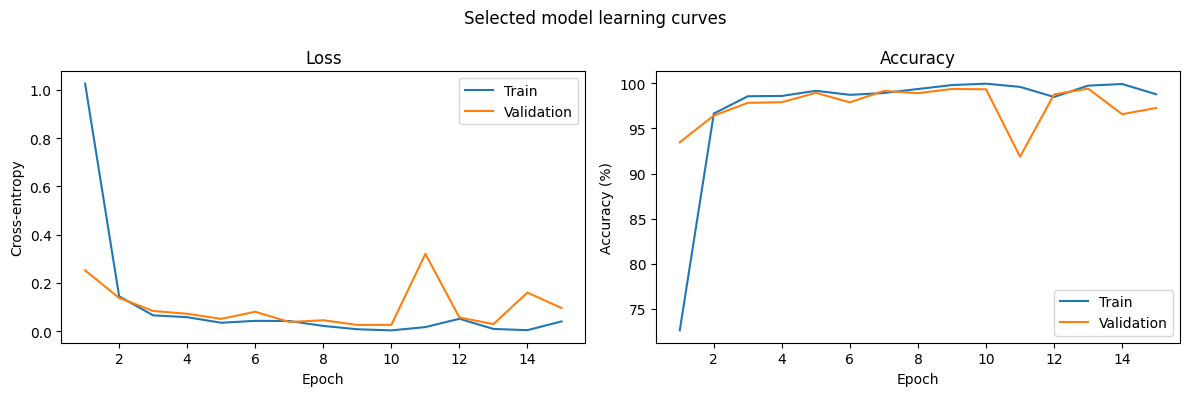

In [13]:
# D — experiments (one change at a time)
# Hint (PyTorch augmentation, no flip):
#   transforms.Compose([Resize, RandomRotation(15), ColorJitter(0.2,0.2),
#                        RandomAffine(0, translate=(0.1,0.1)), ToTensor()])
# TODO

# D: THREE separately measured interventions (only one change from baseline each).
# 1) Augmentation; 2) BatchNorm; 3) inverse-sqrt class-weighted loss.
# These weights use ONLY the training subset, not val/test labels.
weight_values = np.sqrt(train_counts.sum() / (NUM_CLASSES * np.maximum(train_counts, 1)))
weight_values /= weight_values.mean()
CLASS_WEIGHTS = torch.tensor(weight_values, dtype=torch.float32)

models = {'Baseline': baseline_model}
histories = {'Baseline': baseline_history}
val_scores = {'Baseline': baseline_val_acc}
best_epochs = {'Baseline': baseline_best_epoch}
experiments = [
    ('Exp 1: Augmentation', aug_train_loader, False, None),
    ('Exp 2: Batch normalization', train_loader, True, None),
    ('Exp 3: Class-weighted loss', train_loader, False, CLASS_WEIGHTS),
    ('Final: Augmentation + BatchNorm', aug_train_loader, True, None),
]
for name, loader, use_bn, weights in experiments:
    model, hist, best_val, best_epoch = fit_model(
        name, loader, batchnorm=use_bn, class_weights=weights)
    models[name] = model
    histories[name] = hist
    val_scores[name] = best_val
    best_epochs[name] = best_epoch

# Select the final checkpoint exclusively using validation performance.
# Includes baseline in case none of the changes improves validation.
BEST_NAME = max(val_scores, key=val_scores.get)
BEST_MODEL = models[BEST_NAME]
print('\nSelected checkpoint by best validation accuracy:', BEST_NAME)
rows = []
changes = {
    'Baseline': 'No additional technique',
    'Exp 1: Augmentation': 'Rotate/shift/zoom + color jitter',
    'Exp 2: Batch normalization': 'BatchNorm after both convolutions',
    'Exp 3: Class-weighted loss': 'Inverse-sqrt frequency loss weights',
    'Final: Augmentation + BatchNorm': 'Combine augmentation and BatchNorm',
}
for name in ['Baseline'] + [x[0] for x in experiments]:
    rows.append({'Experiment': name, 'Change made': changes[name],
                 'Val accuracy': f'{val_scores[name]:.2%}',
                 'Δ vs baseline (pp)': f'{(val_scores[name]-baseline_val_acc)*100:+.2f}',
                 'Best epoch': best_epochs[name]})
comparison_df = pd.DataFrame(rows)
print('\nPART D RESULTS (measured, not estimated)')
print(comparison_df.to_string(index=False))
print('Selected model:', BEST_NAME)
comparison_df.to_csv(OUTPUT_DIR / 'D_comparison.csv', index=False)
plot_curves(histories[BEST_NAME], 'Selected model learning curves', 'D_best_curves.png')

### Part D results table (fill in)

| Experiment | Change made | Val accuracy | Δ vs baseline |
|---|---|---|---|
| Baseline (Part C) | 	No improvement | 98.89% | — |
| Exp 1 | Data Augmentation | 98.80% | −0.09 pp |
| Exp 2 | Batch Normalization | 99.42% | +0.53 pp |
| Exp 3 | Class-Weighted Loss | 99.12% | +0.23 pp |
| **Final model** | Batch Normalization (Exp 2) | 99.42% | +0.53 pp |


---
## Part E — Evaluate & analyze errors  *(15%)*

**Hints**
- First collect `(y_true, y_pred)` over the whole test set, then everything else is easy.
- `sklearn.metrics.confusion_matrix` and `classification_report` do the heavy lifting.
- "Most-confused pairs" = the largest **off-diagonal** entries of the confusion matrix.
- Look at the actual misclassified images — are the confused signs genuinely similar, or just rare/low-res?

**TODO**
- [ ] E1: compute and display the confusion matrix on the test set
- [ ] E2: find the 3 most-confused class pairs and show example misclassified images
- [ ] E3: explain *why* those confusions happen
- [ ] E4: report per-class accuracy; did the rare classes from A3 suffer?


Final model: Exp 2: Batch normalization
Final official test accuracy: 92.40%

Per-class precision, recall and F1:
                          precision    recall  f1-score   support

             00 Speed 20      0.976     0.667     0.792        60
             01 Speed 30      0.857     0.974     0.912       720
             02 Speed 50      0.923     0.959     0.940       750
             03 Speed 60      0.902     0.900     0.901       450
             04 Speed 70      0.989     0.912     0.949       660
             05 Speed 80      0.796     0.905     0.847       630
         06 End speed 80      0.992     0.833     0.906       150
            07 Speed 100      0.968     0.800     0.876       450
            08 Speed 120      0.853     0.918     0.884       450
           09 No passing      0.972     0.948     0.960       480
     10 No passing >3.5t      0.982     0.983     0.983       660
11 Intersection priority      0.898     0.898     0.898       420
        12 Priority road   

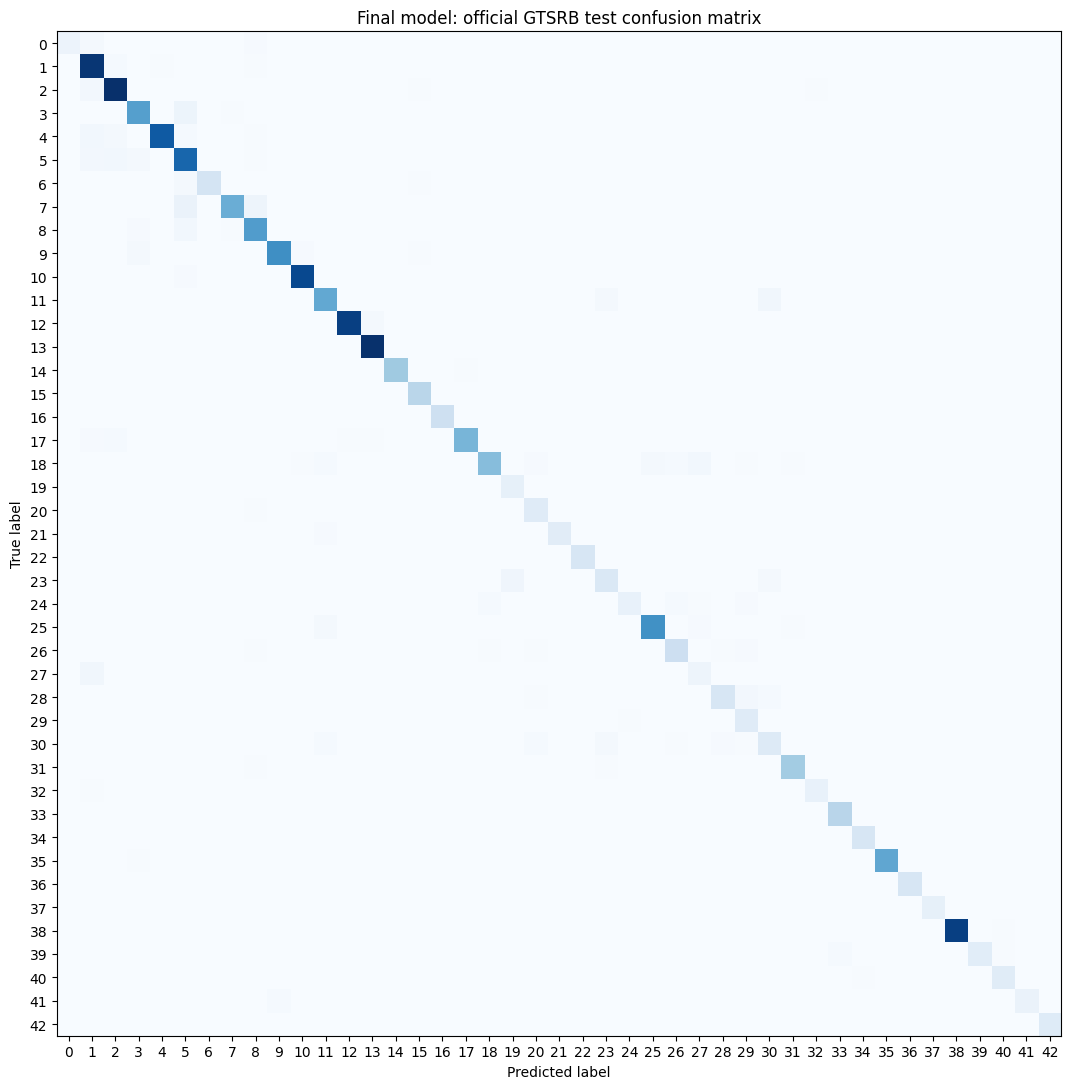


PER-CLASS TEST ACCURACY
 Class ID            Class name  Train frequency (before split)  Test support Test accuracy
        0              Speed 20                             150            60        66.67%
        1              Speed 30                            1500           720        97.36%
        2              Speed 50                            1500           750        95.87%
        3              Speed 60                             960           450        90.00%
        4              Speed 70                            1320           660        91.21%
        5              Speed 80                            1260           630        90.48%
        6          End speed 80                             300           150        83.33%
        7             Speed 100                             960           450        80.00%
        8             Speed 120                             960           450        91.78%
        9            No passing                        

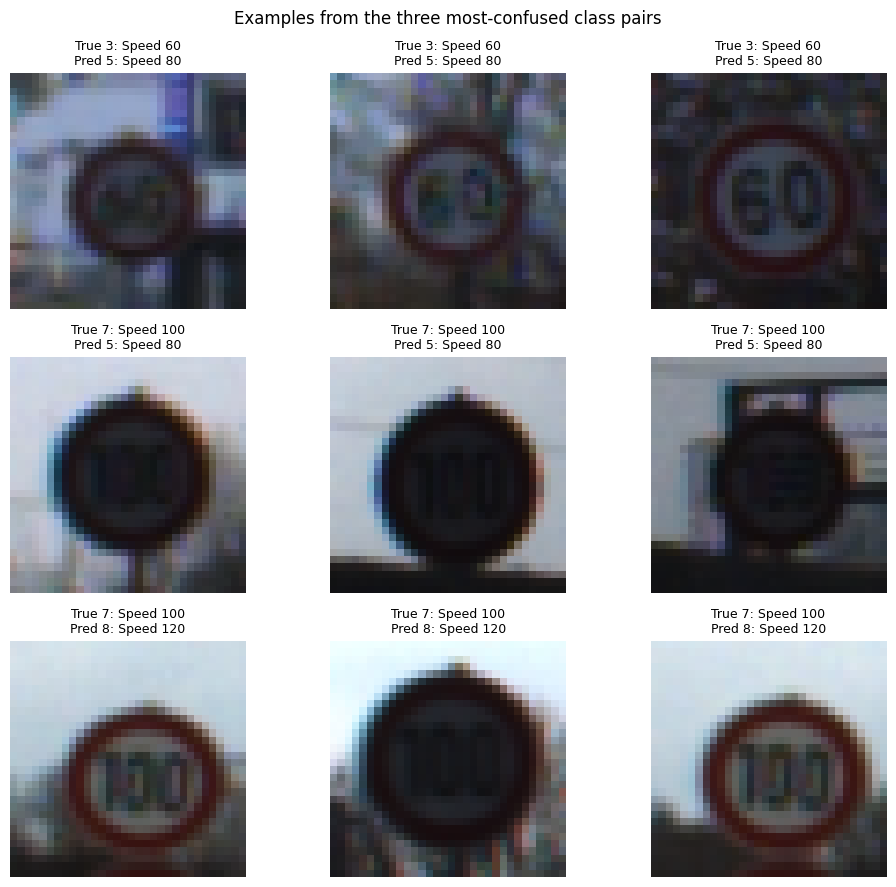

In [14]:
# E — gather predictions, then confusion matrix + per-class report
# Hint: loop the test loader collecting argmax predictions and true labels into two arrays.
#       from sklearn.metrics import confusion_matrix, classification_report
# TODO

# E1/E4: final official test predictions; confusion matrix; class accuracy.
@torch.no_grad()
def collect_predictions(model, loader):
    model.eval()
    truth, pred = [], []
    for x, y in loader:
        logits = model(x.to(DEVICE, non_blocking=True))
        truth.extend(y.numpy().tolist())
        pred.extend(logits.argmax(1).cpu().numpy().tolist())
    return np.array(truth), np.array(pred)

y_true, y_pred = collect_predictions(BEST_MODEL, test_loader)
assert len(y_true) == len(test_dataset)
final_test_acc = (y_true == y_pred).mean()
cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
print('Final model:', BEST_NAME)
print(f'Final official test accuracy: {final_test_acc:.2%}')
print('\nPer-class precision, recall and F1:')
print(classification_report(y_true, y_pred,
                            labels=list(range(NUM_CLASSES)),
                            target_names=[f'{i:02d} {n}' for i, n in enumerate(CLASS_NAMES)],
                            zero_division=0, digits=3))
fig, ax = plt.subplots(figsize=(12, 11))
ConfusionMatrixDisplay(cm, display_labels=np.arange(NUM_CLASSES)).plot(
    ax=ax, cmap='Blues', colorbar=False, values_format='d', include_values=False)
ax.set_title('Final model: official GTSRB test confusion matrix')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'E1_confusion_matrix.png', dpi=160)
plt.show()

per_class_accuracy = np.divide(np.diag(cm), cm.sum(axis=1),
                               out=np.zeros(NUM_CLASSES, dtype=float),
                               where=cm.sum(axis=1) != 0)
per_class_df = pd.DataFrame({
    'Class ID': np.arange(NUM_CLASSES), 'Class name': CLASS_NAMES,
    'Train frequency (before split)': counts,
    'Test support': cm.sum(axis=1), 'Test accuracy': per_class_accuracy
})
print('\nPER-CLASS TEST ACCURACY')
print(per_class_df.to_string(index=False, formatters={'Test accuracy': '{:.2%}'.format}))
per_class_df.to_csv(OUTPUT_DIR / 'E4_per_class_accuracy.csv', index=False)
print('\nThree rarest TRAIN classes and their TEST accuracy:')
for cls in RARE_CLASSES:
    print(f' {cls:2d} {CLASS_NAMES[cls]}: train={counts[cls]}, '
          f'test accuracy={per_class_accuracy[cls]:.2%} (n={cm.sum(axis=1)[cls]})')
print(f'Rare-class mean accuracy: {per_class_accuracy[RARE_CLASSES].mean():.2%}; '
      f'all-class macro accuracy: {per_class_accuracy.mean():.2%}')

# E2: score unordered class pairs by bidirectional off-diagonal confusion counts.
pairs = sorted([(int(cm[a,b] + cm[b,a]), a, b)
                for a in range(NUM_CLASSES) for b in range(a+1, NUM_CLASSES)
                if cm[a,b] + cm[b,a] > 0], reverse=True)[:3]
print('\nThree most-confused class PAIRS (both directions combined):')
for k, (n, a, b) in enumerate(pairs, 1):
    print(f'{k}: {a} ({CLASS_NAMES[a]}) vs {b} ({CLASS_NAMES[b]}) '
          f'-> {n} errors ({a}->{b}: {cm[a,b]}, {b}->{a}: {cm[b,a]})')
if pairs:
    fig, axes = plt.subplots(len(pairs), 3, figsize=(10, 3*len(pairs)), squeeze=False)
    for row, (_, a, b) in enumerate(pairs):
        matching = np.where(((y_true == a) & (y_pred == b)) |
                            ((y_true == b) & (y_pred == a)))[0][:3]
        for ax in axes[row]:
            ax.axis('off')
        for ax, test_idx in zip(axes[row], matching):
            img, _ = test_dataset[int(test_idx)]
            ax.imshow(img.permute(1, 2, 0).numpy())
            ax.set_title(f'True {y_true[test_idx]}: {CLASS_NAMES[y_true[test_idx]]}\n'
                         f'Pred {y_pred[test_idx]}: {CLASS_NAMES[y_pred[test_idx]]}', fontsize=9)
    fig.suptitle('Examples from the three most-confused class pairs')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'E2_confused_examples.png', dpi=150)
    plt.show()
else:
    print('No off-diagonal errors to display.')

**E3 + E4 analysis (write here):** _Why are those pairs confused? Did rare classes suffer?_

The E cell prints the actual three highest-count bidirectional confusion pairs, displays their test images, and compares the three rarest training classes against macro per-class test accuracy. Discuss the pictured errors: low resolution, blur, lighting or similar arrow/speed-limit symbols are plausible explanations, not established causes. The auto-generated short report records the measured counts and class accuracies.

---
## Part F — Stretch goals  *(bonus +10%)*

**Hints**
- Robustness: wrap the test images with added Gaussian noise / blur / brightness shift and re-measure accuracy; plot accuracy vs. corruption strength.
- Explainability: Grad-CAM highlights the pixels that drove the prediction.
- Demo: softmax the logits for one image and print the top-3 classes with confidences.

**TODO (pick one or more)**
- [ ] Robustness curve  ·  [ ] Grad-CAM heatmap  ·  [ ] Top-3 single-image demo


In [16]:
%pip install tabulate

Robustness to Gaussian noise:
  sigma=0.00: test accuracy=92.40%
  sigma=0.05: test accuracy=84.32%
  sigma=0.10: test accuracy=71.39%
  sigma=0.20: test accuracy=51.00%
  sigma=0.30: test accuracy=37.11%


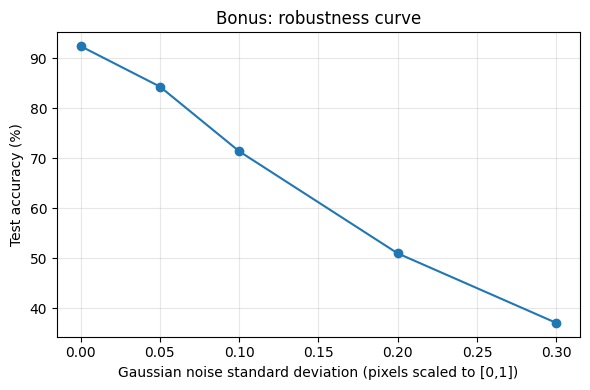


Top-3 prediction demo | true label: 18 (Caution)
 1. 18 Caution: 94.95%
 2. 27 Pedestrians: 4.98%
 3. 26 Traffic lights: 0.07%


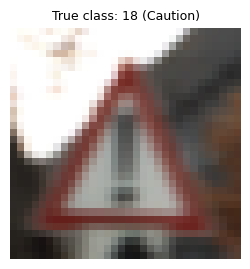


Report saved to: traffic_sign_outputs/report.md
All figures and Part D / per-class CSV files are in: traffic_sign_outputs


In [17]:
# F — your chosen stretch goal(s)
# TODO

# F BONUS: (1) reproducible Gaussian-noise robustness curve; (2) top-3 demo.
@torch.no_grad()
def noise_accuracy(model, loader, sigma):
    model.eval()
    correct, total = 0, 0
    generator = torch.Generator(device='cpu').manual_seed(SEED)
    for x, y in loader:
        if sigma > 0:
            noise = torch.randn(x.shape, generator=generator) * sigma
            x = (x + noise).clamp(0.0, 1.0)
        logits = model(x.to(DEVICE, non_blocking=True))
        correct += (logits.argmax(1).cpu() == y).sum().item()
        total += len(y)
    return correct / total

noise_levels = [0.0, 0.05, 0.10, 0.20, 0.30]
noise_scores = [noise_accuracy(BEST_MODEL, test_loader, s) for s in noise_levels]
print('Robustness to Gaussian noise:')
for s, score in zip(noise_levels, noise_scores):
    print(f'  sigma={s:.2f}: test accuracy={score:.2%}')
plt.figure(figsize=(6,4))
plt.plot(noise_levels, 100*np.array(noise_scores), marker='o')
plt.xlabel('Gaussian noise standard deviation (pixels scaled to [0,1])')
plt.ylabel('Test accuracy (%)')
plt.title('Bonus: robustness curve')
plt.grid(alpha=.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'F_robustness_curve.png', dpi=150)
plt.show()

# Top-3 ranked predictions for one unseen official test image.
example_id = SEED % len(test_dataset)
image_tensor, true_id = test_dataset[example_id]
BEST_MODEL.eval()
with torch.no_grad():
    logits = BEST_MODEL(image_tensor.unsqueeze(0).to(DEVICE))
    probabilities = torch.softmax(logits, dim=1)[0]
    scores, predicted_ids = torch.topk(probabilities, 3)
print(f'\nTop-3 prediction demo | true label: {true_id} ({CLASS_NAMES[true_id]})')
for rank, (cls, p) in enumerate(zip(predicted_ids.cpu().tolist(), scores.cpu().tolist()), 1):
    print(f' {rank}. {cls:2d} {CLASS_NAMES[cls]}: {p:.2%}')
plt.figure(figsize=(3,3))
plt.imshow(image_tensor.permute(1,2,0).numpy())
plt.title(f'True class: {true_id} ({CLASS_NAMES[true_id]})', fontsize=9)
plt.axis('off')
plt.show()

# Generate a concise, evidence-based submission report from real notebook results.
rare_mean = per_class_accuracy[RARE_CLASSES].mean()
macro_mean = per_class_accuracy.mean()
pair_lines = '\n'.join(
    f'- {CLASS_NAMES[a]} (class {a}) vs {CLASS_NAMES[b]} (class {b}): '
    f'{n} combined misclassifications.' for n, a, b in pairs) or '- No misclassifications.'
if rare_mean + .03 < macro_mean:
    rare_comment = 'The three rarest training classes performed worse than the macro average.'
else:
    rare_comment = 'The three rarest training classes were not substantially worse than the macro average.'
report = f'''# CNN Traffic Sign Recognition — Short Assignment Report

## Dataset and preprocessing
GTSRB includes 43 sign categories. The loaded training pool contains {len(raw_train):,} images and the untouched official test set has {len(test_dataset):,}. We used 32×32 RGB images to limit computation while retaining enough structure for the small CNN; `ToTensor()` scaled pixels to [0,1]. The training pool was divided into a stratified 80/20 training/validation split using seed {SEED}. Validation and test images were neither augmented nor shuffled.

The three rarest training-pool classes were {', '.join(f'{i} ({CLASS_NAMES[i]}; {counts[i]} images)' for i in RARE_CLASSES)}. Their frequencies motivated a class-weighted-loss experiment.

## Baseline and learning curves
The baseline uses two Conv-ReLU-MaxPool blocks (32 and 64 channels) followed by dense layers (128 hidden units and 43 raw logits), trained with Adam and cross-entropy for up to {EPOCHS} epochs. Its best validation accuracy was **{baseline_val_acc:.2%}**, and test accuracy was **{baseline_test_acc:.2%}**. The last-epoch training/validation accuracy difference was **{gap*100:+.2f} percentage points**. {curve_reading}

## Controlled improvement experiments
Each isolated experiment differs from the baseline in one component. Validation accuracy, not test accuracy, determined model selection.

{comparison_df.to_markdown(index=False)}

The selected checkpoint was **{BEST_NAME}**, with validation accuracy **{val_scores[BEST_NAME]:.2%}**. The final official test accuracy was **{final_test_acc:.2%}**. Whether augmentation and normalization helped depends on their measured changes in the table; class weighting was evaluated independently rather than assumed beneficial.

## Test errors and reflection
The three highest-count unordered confusion pairs were:
{pair_lines}

The images in `E2_confused_examples.png` should be inspected for visual similarity, scale, blur, illumination and class-specific sign details. These factors are possible explanations, not proven causal mechanisms. The rare-class mean accuracy was **{rare_mean:.2%}** compared with **{macro_mean:.2%}** macro accuracy. {rare_comment}

A limitation is that the development set comes from the GTSRB training pool, and this simple CNN does not explicitly address unknown signs or different countries. The final system should be assessed for domain shift and noisy camera images before deployment; Part F gives one preliminary noise test.
'''
(OUTPUT_DIR / 'report.md').write_text(report, encoding='utf-8')
print('\nReport saved to:', OUTPUT_DIR / 'report.md')
print('All figures and Part D / per-class CSV files are in:', OUTPUT_DIR)

---
## Global hints
- Get the whole pipeline running on a **small subset** before scaling up — a model that trains badly beats a pipeline that won't run.
- "Better" only means something relative to your Part C baseline.
- Don't let test data leak into training or into augmentation statistics.
- `CrossEntropyLoss` wants raw logits; don't add a softmax before it.
- PyTorch: `model.train()` vs `model.eval()`, and `optimizer.zero_grad()` every step.


## What to submit & grading
**Submit** this completed notebook (code + outputs visible) and a short report (≈1–2 pages): preprocessing choices, the Part D comparison table, your confusion-matrix analysis, and a reflection on what helped most. State your **final test accuracy**.

| Component | Weight |
|---|---|
| A — Data exploration | 10% |
| B — Preprocessing | 10% |
| C — Baseline CNN | 25% |
| D — Improvements + comparison table | 30% |
| E — Evaluation & error analysis | 15% |
| Report clarity & reflection | 10% |
| F — Stretch goals | +10% bonus |

Grades reward **deliberate, measured** improvement and clear reasoning — not just the highest accuracy. A modest CNN reaches ~95%+ test accuracy here; well-tuned models exceed 98–99%.
